# Step 16 — Does weighting the experts beat averaging them?

Mean-pooling gives every expert the same weight on every row. But each expert sees its own random
~70% of the columns, so for any given row some experts are looking at the useful features and some
are not. The supervisor's proposal: let each expert output a **confidence** `c_i` alongside its
prediction `y_i`, and aggregate as `sum(y_i * c_i) / sum(c_i)`.

Notebook 15 already tested a strictly *more* powerful version of this idea — attention, which lets
experts weight each other per row — and found it does not beat averaging at matched size. This
notebook asks whether a much cheaper, order-invariant version does, and splits the question into
two parts that notebook 15 could not separate.

### The two questions

1. **Are some experts simply better than others?** (a fixed weight per expert, same for every row)
2. **Does the weighting have to depend on the input?** (a weight per expert *per row*)

### Arms

All share the same 16 feature-bagged experts + PLR embeddings, and for a given seed the experts are
bit-identical across arms.

| Arm | Aggregation | Training objective | Params (CA) |
|---|---|---|---|
| `meanpool` | average the expert **embeddings**, then predict once | criterion on the prediction | ~24.6k |
| `meanpool_ncl` | predict per expert, then average | mean of the 16 **per-expert** losses | ~24.6k |
| `conf_uniform` | predict per expert, then average | criterion on the **ensemble** prediction | ~24.6k |
| `conf_static` | `softmax(a)` weights, `a` learned, same for every row | criterion on the ensemble prediction | +16 |
| `conf_dynamic` | `softmax(W z_i)` weights, computed per row from each expert's own token | criterion on the ensemble prediction | +33 |

### `conf_uniform` is the control, and it is the whole reason this notebook is readable

`conf_static` and `conf_dynamic` need the loss to act on the **ensemble** prediction, otherwise the
weights get no gradient at all and sit at their uniform initialisation forever. But `meanpool_ncl`
trains on the *mean of per-expert losses*. So comparing `conf_static` against `meanpool_ncl` would
confound "weighting helped" with "the objective changed".

`conf_uniform` fixes that: its forward pass is **bit-identical** to `meanpool_ncl` (asserted in
`model.py`'s self-test) and only its loss differs. So:

* `conf_uniform` vs `meanpool_ncl` isolates the **objective** change.
* `conf_static` / `conf_dynamic` vs `conf_uniform` isolates the **weighting**, which is the question.

Both learned arms are zero-initialised, so they *start* exactly at uniform weights and can only
move away from mean-pooling if the data pays them to.

### Pre-registered decision rule (fixed before running)

> `conf_static` or `conf_dynamic` beats `conf_uniform` (paired t-test, p<0.05) on **3 or more of
> the 4 datasets** -> confidence weighting earns its place. On 1 or fewer -> it does not.

Taking the better of the two arms per dataset deliberately favours a positive verdict, so a
negative one is conservative.

### A limitation to state up front

Output-level pooling is only defined for a scalar prediction per expert, so **every arm here is
restricted to regression and binary classification**. Jannis and Covertype are multiclass and
cannot be tested — which matters, because Covertype is the project's known weak spot. Extending
output-level pooling to multiclass is a prerequisite for ever applying this there.

## 0. Setup

In [1]:
import os, sys, time, json, subprocess, warnings
warnings.filterwarnings("ignore")
PROJECT_DIR = os.getcwd(); sys.path.insert(0, PROJECT_DIR)
os.environ["PYTHONPATH"] = PROJECT_DIR + os.pathsep + os.environ.get("PYTHONPATH", "")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

import benchmarks, benchmarks_rtdl
from training import get_device
from weak_learners import WeakLearnerConfig
from attention import AttentionConfig
from embeddings import EmbeddingConfig
from model import make_arm
from results import save_report
from plotting import apply_style, plot_bar_comparison, role_color

DEVICE = get_device()

# Knobs, overridable from the shell so a headless run needs no edits. Smoke test:
#   SRP_SUBSAMPLE=1500 SRP_SEEDS=2 SRP_EPOCHS=3 SRP_PATIENCE=2 jupyter nbconvert --execute ...
# NOTE: no multiclass datasets -- pool_level="output" needs one scalar prediction per expert.
KEYS      = os.environ.get("SRP_KEYS", "CA,AD,HI,SA").split(",")
ARMS      = os.environ.get("SRP_ARMS", "meanpool,meanpool_ncl,conf_uniform,conf_static,conf_dynamic").split(",")
SEEDS     = tuple(range(int(os.environ.get("SRP_SEEDS", "5"))))
EPOCHS    = int(os.environ.get("SRP_EPOCHS", "200"))
PATIENCE  = int(os.environ.get("SRP_PATIENCE", "20"))
SUBSAMPLE = int(os.environ.get("SRP_SUBSAMPLE", "0")) or None

# Identical for every arm (notebook 15's architecture and budget, unchanged).
ENS_KW   = dict(num_learners=16, hidden_dim=16, embed_dim=32, depth=1, dropout=0.1, feature_frac=0.7)
ATT_KW   = dict(embed_dim=32, num_heads=4, attn_depth=2, ff_mult=4, dropout=0.1, need_weights=False)
EMB_KW   = dict(mode="periodic", d_embedding=8, n_frequencies=16, sigma=0.1)
TRAIN_KW = dict(epochs=EPOCHS, patience=PATIENCE, lr=1e-3, batch_size=512, weight_decay=1e-4)

LOADER = {"CA": benchmarks_rtdl, "AD": benchmarks_rtdl, "JA": benchmarks_rtdl,
          "HI": benchmarks, "SA": benchmarks, "FB": benchmarks}
ARM_LABEL = {"meanpool": "Mean-pool\n(embedding)", "meanpool_ncl": "Average preds\n(per-expert loss)",
             "conf_uniform": "Average preds\n(ensemble loss)", "conf_static": "Learned weights\n(static)",
             "conf_dynamic": "Learned weights\n(per row)"}
ARM_COLOR = {a: role_color(a) for a in ARM_LABEL}
WEIGHTED = [a for a in ("conf_static", "conf_dynamic") if a in ARMS]
CONTROL = "conf_uniform"

THREADS_PER_JOB = 2
N_JOBS = int(os.environ.get("SRP_JOBS", "0")) or (
    3 if DEVICE.type == "cuda" else max(1, min(8, (os.cpu_count() or 2) // THREADS_PER_JOB)))

RUN_DIR = os.path.join(PROJECT_DIR, "runs"); os.makedirs(RUN_DIR, exist_ok=True)
STAMP = time.strftime("%Y%m%d_%H%M%S")
LOG_PATH = os.path.join(RUN_DIR, f"17_progress_{STAMP}.log")
_latest = os.path.join(RUN_DIR, "17_progress.log")
if os.path.islink(_latest) or os.path.exists(_latest):
    os.remove(_latest)
os.symlink(os.path.basename(LOG_PATH), _latest)
REPORT_DIR = os.path.join(PROJECT_DIR, "results", "confidence_weighting")
FIG_DIR = os.path.join(os.path.dirname(PROJECT_DIR), "figures")

def log(msg):
    print(msg, flush=True)
    with open(LOG_PATH, "a") as f: f.write(time.strftime("%H:%M:%S ") + msg + "\n")
def show(df, fmt=None, style=None):
    try:
        s = df.style.format(fmt or {}, na_rep="—"); display(style(s) if style else s)
    except (AttributeError, ImportError):
        display(df.round(4))

apply_style()
gpu = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only"
log(f"device: {DEVICE} ({gpu}) | keys={KEYS} | arms={ARMS} | seeds={len(SEEDS)} | "
    f"epochs<={EPOCHS} patience={PATIENCE} | {N_JOBS} workers")
if SUBSAMPLE:
    log(f"SMOKE TEST: {SUBSAMPLE} rows per split -- numbers below are NOT real results.")

device: cuda (NVIDIA RTX A4000) | keys=['CA', 'AD', 'HI', 'SA'] | arms=['meanpool', 'meanpool_ncl', 'conf_uniform', 'conf_static', 'conf_dynamic'] | seeds=5 | epochs<=200 patience=20 | 3 workers


## 1. Is the implementation correct? Run the module's own self-tests first

`model.py` asserts the things this whole notebook rests on: that `conf_uniform`'s forward is
bit-identical to `meanpool_ncl`'s, that the learned weights are softmax-normalised, that zero-init
starts them exactly at uniform, and — the one that matters most — that the confidence weights
**actually receive gradient**. Without that last property every learned arm would silently be a
copy of the control.

In [2]:
for module in ("model.py", "ncl.py"):
    out = subprocess.run([sys.executable, module], cwd=PROJECT_DIR, capture_output=True, text=True)
    text = out.stdout + out.stderr
    n_pass, n_fail = text.count("PASS"), text.count("FAIL")
    log(f"  {module:14s} {n_pass} PASS, {n_fail} FAIL")
    assert out.returncode == 0 and n_fail == 0 and n_pass > 0, text[-3000:]
log("self-tests passed: control arm is forward-identical, weights normalised, gradients flow")

  model.py       19 PASS, 0 FAIL


  ncl.py         5 PASS, 0 FAIL


self-tests passed: control arm is forward-identical, weights normalised, gradients flow


## 2. Data — exact published splits (regression / binary only)

In [3]:
DATA, ARRAYS = {}, {}
for k in KEYS:
    d = LOADER[k].load_benchmark(k)
    assert d.task != "multiclass", (
        f"{k} is multiclass; pool_level='output' needs one scalar prediction per expert")
    a = d.arrays()
    if SUBSAMPLE:
        n = SUBSAMPLE
        a = {"Xtr": a["Xtr"][:n], "ytr": a["ytr"][:n], "Xva": a["Xva"][:n // 2], "yva": a["yva"][:n // 2],
             "Xte": a["Xte"][:n], "yte": a["yte"][:n]}
    DATA[k], ARRAYS[k] = d, a
    log(d.summary())
HIB = {k: LOADER[k].higher_is_better(k) for k in KEYS}
METRIC = {k: ("rmse" if DATA[k].task == "regression" else "acc") for k in KEYS}

CA California Housing regression features=  8 train=13,209 val=3,303 test=4,128


AD Adult              binary     features=108 train=26,048 val=6,513 test=16,281  classes=2


HI Higgs Small        binary     features= 28 train=62,751 val=15,688 test=19,610  classes=2


SA Santander          binary     features=200 train=128,000 val=32,000 test=40,000  classes=2


## 3. What does the weighting actually cost?

The learned arms add `K` (static) or `embed_dim + 1` (dynamic) parameters on top of the control.
That is a rounding error against ~24,600 — which is the point. Unlike notebook 15's attention arms
(+26,048 params, needing a whole size-matched control arm), nothing here needs capacity matching,
so any difference is attributable to the mechanism.

In [4]:
rows = []
for k in KEYS:
    d = DATA[k]
    row = {"dataset": d.label}
    for arm in ARMS:
        torch.manual_seed(0)
        m = make_arm(arm, d.n_features, WeakLearnerConfig(**ENS_KW, seed=0, batched=True),
                     AttentionConfig(**ATT_KW), task=d.task, output_dim=d.output_dim,
                     embedding=EmbeddingConfig(**EMB_KW))
        row[arm] = m.num_parameters()
    rows.append(row)
PARAMS = pd.DataFrame(rows).set_index("dataset")
show(PARAMS, {a: "{:,.0f}" for a in ARMS})

if CONTROL in ARMS:
    for ds, r in PARAMS.iterrows():
        for arm in WEIGHTED:
            extra = r[arm] - r[CONTROL]
            assert 0 < extra <= 64, f"{ds}/{arm}: unexpected +{extra} params over {CONTROL}"
    log(f"cost check passed: every weighted arm is within 64 parameters of {CONTROL} "
        f"-- no capacity confound to control for")

,meanpool,meanpool_ncl,conf_uniform,conf_static,conf_dynamic
dataset,,,,,
California Housing,"24,641","24,641","24,641","24,657","24,674"
Adult,"196,001","196,001","196,001","196,017","196,034"
Higgs Small,"58,913","58,913","58,913","58,929","58,946"
Santander,"352,833","352,833","352,833","352,849","352,866"


cost check passed: every weighted arm is within 64 parameters of conf_uniform -- no capacity confound to control for


## 4. Train everything

One job = one (dataset, arm, seed). Each job records the test score, the best epoch (to catch
undertraining), wall-clock time, and — for the weighted arms — the **entropy of the learned
weights**, normalised so that 1.0 means perfectly uniform.

That entropy is the diagnostic that makes a null result interpretable. A weighted arm that scores
the same as the control could mean either "weighting does not help" or "the weights never moved".
Only the entropy tells those two apart.

In [5]:
def run_one(key, arm, seed, arrays, task, output_dim, n_features, y_std,
            ens_kw, att_kw, emb_kw, train_kw, device_str, project_dir, threads):
    import sys, time
    if project_dir not in sys.path: sys.path.insert(0, project_dir)
    import numpy as np, torch
    from weak_learners import WeakLearnerConfig
    from attention import AttentionConfig
    from embeddings import EmbeddingConfig
    from model import make_arm
    from training import train_model, evaluate, to_tensors
    torch.set_num_threads(threads)
    data = to_tensors(arrays, device_str)
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_arm(arm, n_features, WeakLearnerConfig(**ens_kw, seed=seed, batched=True),
                     AttentionConfig(**att_kw), task=task, output_dim=output_dim,
                     embedding=EmbeddingConfig(**emb_kw))
    t0 = time.time()
    model, hist = train_model(model, data, seed=seed, **train_kw)
    test = evaluate(model, data["Xte"], arrays["yte"], task)
    score = test["rmse"] * y_std if task == "regression" else test["acc"]   # RMSE in original units

    entropy = w_min = w_max = None
    if getattr(model, "conf", None) is not None:
        model.eval()
        with torch.no_grad():
            w = model(data["Xte"][:2048])["conf"]            # (B, K), rows sum to 1
        K = w.shape[1]
        p = w.clamp_min(1e-12)
        entropy = float((-(p * p.log()).sum(-1) / np.log(K)).mean())   # 1.0 = uniform
        mean_w = w.mean(0)
        w_min, w_max = float(mean_w.min()), float(mean_w.max())
    return {"key": key, "arm": arm, "seed": seed, "score": score,
            "best_epoch": hist["best_epoch"] + 1, "epochs_run": hist["epochs_run"],
            "best_val_loss": float(hist["val"][hist["best_epoch"]]),
            "seconds": time.time() - t0, "n_params": model.num_parameters(),
            "entropy": entropy, "w_min": w_min, "w_max": w_max}

SLOW = {"SA": 0, "HI": 1, "AD": 2, "CA": 3}
jobs = [(k, a, s) for k in KEYS for a in ARMS for s in SEEDS]
jobs.sort(key=lambda j: (SLOW.get(j[0], 9), j[1]))          # slowest datasets first
log(f"{len(jobs)} runs on {N_JOBS} workers ({DEVICE}) ...")

t0, RES = time.time(), []
for r in Parallel(n_jobs=N_JOBS, return_as="generator")(
        delayed(run_one)(k, a, s, ARRAYS[k], DATA[k].task, DATA[k].output_dim, DATA[k].n_features,
                         DATA[k].y_std, ENS_KW, ATT_KW, EMB_KW, TRAIN_KW, str(DEVICE),
                         PROJECT_DIR, THREADS_PER_JOB)
        for k, a, s in jobs):
    RES.append(r)
    save_report(os.path.join(REPORT_DIR, r["key"], r["arm"], f"seed{r['seed']}"),
                dataset=r["key"], label=DATA[r["key"]].label, arm=r["arm"], seed=r["seed"],
                source="reproduced", source_ref="notebook 17 (confidence weighting)"
                + (" [SMOKE TEST]" if SUBSAMPLE else ""),
                config={"ens": ENS_KW, "att": ATT_KW, "emb": EMB_KW, "train": TRAIN_KW},
                n_parameters=r["n_params"], metrics={"test": {METRIC[r["key"]]: r["score"]}},
                champion_metric=f"test_{METRIC[r['key']]}", champion_value=r["score"],
                higher_is_better=HIB[r["key"]], time_seconds=r["seconds"], checkpoint=None)
    ent = f"  entropy {r['entropy']:.4f}" if r["entropy"] is not None else ""
    log(f"  [{len(RES):3d}/{len(jobs)}] {r['key']} {r['arm']:14s} seed {r['seed']}  "
        f"{METRIC[r['key']]} {r['score']:.4f}  best epoch {r['best_epoch']:3d}/{r['epochs_run']:3d}"
        f"{ent}  ({r['seconds']/60:.1f} min)  elapsed {(time.time()-t0)/60:.1f} min")
R = pd.DataFrame(RES)
log(f"all runs done in {(time.time()-t0)/60:.1f} min")

100 runs on 3 workers (cuda) ...


/media/homes/latif/SRP/v4/training.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return {k: torch.as_tensor(np.ascontiguousarray(v)).to(dev) for k, v in arrays.items()}
/media/homes/latif/SRP/v4/training.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/

  [  1/100] SA conf_dynamic   seed 0  acc 0.9220  best epoch   3/ 23  entropy 0.9878  (1.5 min)  elapsed 1.5 min


  [  2/100] SA conf_dynamic   seed 1  acc 0.9224  best epoch   5/ 25  entropy 0.9658  (1.6 min)  elapsed 1.6 min


  [  3/100] SA conf_dynamic   seed 2  acc 0.9221  best epoch   4/ 24  entropy 0.9941  (1.5 min)  elapsed 1.6 min


...

  [ 97/100] CA meanpool_ncl   seed 1  rmse 0.5103  best epoch 153/173  (0.7 min)  elapsed 27.7 min


  [ 98/100] CA meanpool_ncl   seed 2  rmse 0.4813  best epoch 192/200  (0.8 min)  elapsed 27.9 min


  [ 99/100] CA meanpool_ncl   seed 3  rmse 0.4978  best epoch 159/179  (0.7 min)  elapsed 28.1 min


  [100/100] CA meanpool_ncl   seed 4  rmse 0.5186  best epoch 196/200  (0.8 min)  elapsed 28.5 min


all runs done in 28.5 min


## 5. Did every run actually finish learning?

A run whose best epoch falls within the last `PATIENCE` epochs of the cap was still improving when
training stopped, so its score understates that arm. This is the flaw that made notebook 08's
California Housing result wrong.

In [6]:
R["undertrained"] = R["best_epoch"] > (EPOCHS - PATIENCE)
flag = R[R.undertrained]
if len(flag):
    log(f"WARNING: {len(flag)} run(s) may be undertrained (best epoch near the {EPOCHS}-epoch cap):")
    show(flag[["key", "arm", "seed", "best_epoch", "epochs_run"]])
else:
    log(f"convergence check passed: every run early-stopped well before the {EPOCHS}-epoch cap")
show(R.groupby(["key", "arm"])["best_epoch"].agg(["mean", "max"]).unstack("arm").round(0))

,key,arm,seed,best_epoch,epochs_run
94,CA,meanpool,4,193,200
95,CA,meanpool_ncl,0,195,200
97,CA,meanpool_ncl,2,192,200
99,CA,meanpool_ncl,4,196,200


## 6. Results

In [7]:
agg = R.groupby(["key", "arm"])["score"].agg(["mean", "std"])
table = pd.DataFrame({DATA[k].label + (" (RMSE↓)" if not HIB[k] else " (acc↑)"):
                      [f"{agg.loc[(k, a), 'mean']:.4f} ± {agg.loc[(k, a), 'std']:.4f}" for a in ARMS]
                      for k in KEYS}, index=[ARM_LABEL[a].replace(chr(10), " ") for a in ARMS])
print(f"Test scores, mean ± std over {len(SEEDS)} seeds")
show(table)

mins = R.groupby(["key", "arm"])["seconds"].mean().unstack("arm")[ARMS] / 60
mins.index = [DATA[k].label for k in mins.index]
print("\nMean minutes per run")
show(mins, {a: "{:.1f}" for a in ARMS})

Test scores, mean ± std over 5 seeds


,California Housing (RMSE↓),Adult (acc↑),Higgs Small (acc↑),Santander (acc↑)
Mean-pool (embedding),0.4796 ± 0.0108,0.8594 ± 0.0005,0.7250 ± 0.0015,0.9225 ± 0.0006
Average preds (per-expert loss),0.5014 ± 0.0141,0.8631 ± 0.0014,0.7232 ± 0.0021,0.9203 ± 0.0009
Average preds (ensemble loss),0.4730 ± 0.0113,0.8602 ± 0.0009,0.7251 ± 0.0017,0.9222 ± 0.0005
Learned weights (static),0.4720 ± 0.0101,0.8601 ± 0.0011,0.7238 ± 0.0017,0.9222 ± 0.0002
Learned weights (per row),0.4725 ± 0.0103,0.8596 ± 0.0011,0.7239 ± 0.0013,0.9222 ± 0.0002



Mean minutes per run


arm,meanpool,meanpool_ncl,conf_uniform,conf_static,conf_dynamic
Adult,0.2,1.2,0.2,0.2,0.2
California Housing,0.5,0.7,0.3,0.3,0.4
Higgs Small,0.5,2.4,0.4,0.5,0.5
Santander,1.4,2.2,1.5,1.5,1.5


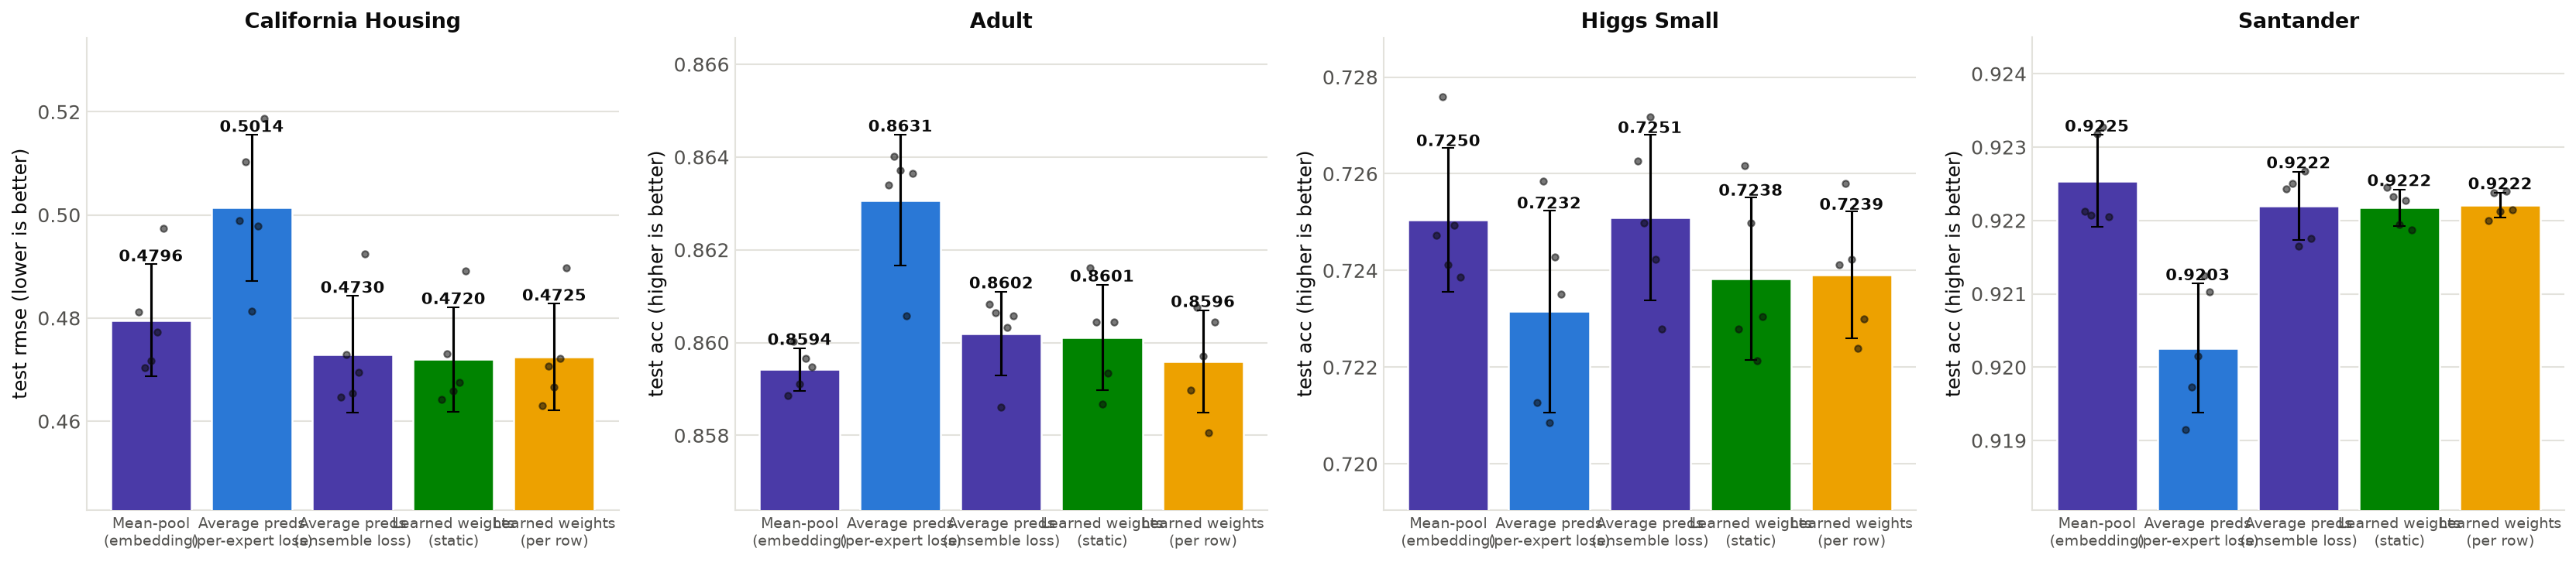

In [8]:
fig, axes = plt.subplots(1, len(KEYS), figsize=(5.6 * len(KEYS), 5.0))
axes = np.atleast_1d(axes)
for ax, k in zip(axes, KEYS):
    means = [agg.loc[(k, a), "mean"] for a in ARMS]
    stds = [agg.loc[(k, a), "std"] for a in ARMS]
    seeds = [R[(R.key == k) & (R.arm == a)]["score"].values for a in ARMS]
    plot_bar_comparison([ARM_LABEL[a] for a in ARMS], means, stds=stds,
                        colors=[ARM_COLOR[a] for a in ARMS], seed_values=seeds,
                        ylabel=f"test {METRIC[k]} ({'higher' if HIB[k] else 'lower'} is better)",
                        title=DATA[k].label, ax=ax)
    lo = min(m - (s if s == s else 0) for m, s in zip(means, stds))
    hi = max(m + (s if s == s else 0) for m, s in zip(means, stds))
    pad = (hi - lo) * 0.35 + 1e-6
    ax.set_ylim(lo - pad, hi + pad)
    ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
if not SUBSAMPLE:
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIG_DIR, "confidence_weighting.pdf"), dpi=200)
    fig.savefig(os.path.join(FIG_DIR, "confidence_weighting.png"), dpi=200)
plt.show()

## 7. Paired significance tests

For each dataset: difference per seed (same seed = same experts), paired t-test over the seeds.
Differences are signed so that **positive always means A is better**, whether the metric is
accuracy or RMSE.

The first row is the objective change on its own; it is *not* part of the decision rule. The rows
that answer the question are the ones against `conf_uniform`.

In [9]:
COMPARISONS = [
    ("Objective only: ensemble loss vs per-expert loss", "conf_uniform", "meanpool_ncl"),
    ("Pooling point: predict-then-average vs average-then-predict", "conf_uniform", "meanpool"),
    ("Static weighting vs uniform",                      "conf_static",  "conf_uniform"),
    ("Per-row weighting vs uniform",                     "conf_dynamic", "conf_uniform"),
    ("Does weighting need the input? per-row vs static", "conf_dynamic", "conf_static"),
]
COMPARISONS = [c for c in COMPARISONS if c[1] in ARMS and c[2] in ARMS]

rows = []
for k in KEYS:
    wide = R[R.key == k].pivot(index="seed", columns="arm", values="score")
    sign = 1.0 if HIB[k] else -1.0
    for name, a, b in COMPARISONS:
        d = sign * (wide[a] - wide[b]).values
        p = stats.ttest_rel(wide[a], wide[b]).pvalue if len(d) > 1 else np.nan
        verdict = ("A better" if p < 0.05 and d.mean() > 0 else
                   "B better" if p < 0.05 and d.mean() < 0 else "no real difference")
        rows.append({"dataset": DATA[k].label, "comparison": name, "A": a, "B": b,
                     "mean advantage of A": d.mean(), "A wins": f"{int((d > 0).sum())}/{len(d)}",
                     "p": p, "verdict": verdict})
TESTS = pd.DataFrame(rows)
show(TESTS.set_index(["comparison", "dataset"]).drop(columns=["A", "B"]).sort_index(),
     {"mean advantage of A": "{:+.4f}", "p": "{:.3f}"},
     style=lambda s: s.map(lambda v: {"A better": "background-color:#d8f5e3",
                                      "B better": "background-color:#fbdada"}.get(v, ""),
                           subset=["verdict"]))

### 7.1 Pooled across all datasets

The per-dataset tests have only 5 seeds each. Pooling all (dataset, seed) pairs gives one stronger
test per comparison. To pool datasets with different metrics, each difference is expressed as a
**percentage of the baseline arm's score** (sign-corrected, positive = A better), then a Wilcoxon
signed-rank test asks whether A is consistently ahead.

In [10]:
rows = []
for name, a, b in COMPARISONS:
    rel = []
    for k in KEYS:
        wide = R[R.key == k].pivot(index="seed", columns="arm", values="score")
        sign = 1.0 if HIB[k] else -1.0
        rel += list(sign * (wide[a] - wide[b]) / wide[b].abs() * 100)
    rel = np.array(rel)
    p = stats.wilcoxon(rel).pvalue if len(rel) >= 6 and np.any(rel != 0) else np.nan
    rows.append({"comparison": name, "pairs": len(rel), "median % advantage of A": np.median(rel),
                 "A wins": f"{int((rel > 0).sum())}/{len(rel)}", "Wilcoxon p": p})
POOLED = pd.DataFrame(rows).set_index("comparison")
show(POOLED, {"median % advantage of A": "{:+.2f}%", "Wilcoxon p": "{:.4f}"})

,pairs,median % advantage of A,A wins,Wilcoxon p
comparison,,,,
Objective only: ensemble loss vs per-expert loss,20,+0.16%,12/20,0.0637
Pooling point: predict-then-average vs average-then-predict,20,+0.06%,12/20,0.2024
Static weighting vs uniform,20,-0.01%,10/20,0.8124
Per-row weighting vs uniform,20,-0.01%,9/20,0.6477
Does weighting need the input? per-row vs static,20,+0.00%,10/20,0.7172


## 8. Did the weights actually learn anything?

Normalised entropy of the learned weights: **1.0 means perfectly uniform**, i.e. the arm reproduces
mean-pooling exactly. Lower means the model committed to some experts over others.

This is what separates "weighting does not help" from "the weights never moved". If an arm scores
like the control *and* its entropy is ~1.0, the mechanism was never exercised and the right
follow-up is a bigger learning rate on those parameters — not a conclusion.

In [11]:
if WEIGHTED:
    ent = R[R.arm.isin(WEIGHTED)].groupby(["key", "arm"])[["entropy", "w_min", "w_max"]].mean()
    ent = ent.round(4).unstack("arm")
    ent.index = [DATA[k].label for k in ent.index]
    print("Learned weight entropy (1.0 = uniform = identical to averaging), and the mean "
          "smallest/largest expert weight")
    show(ent)

    flat = R[R.arm.isin(WEIGHTED)].groupby("arm")["entropy"].mean()
    for arm, e in flat.items():
        verdict = ("weights barely moved -- treat any null result as INCONCLUSIVE"
                   if e > 0.995 else "weights moved away from uniform")
        print(f"  {arm:14s} mean entropy {e:.4f}  ->  {verdict}")

Learned weight entropy (1.0 = uniform = identical to averaging), and the mean smallest/largest expert weight


  conf_dynamic   mean entropy 0.9819  ->  weights moved away from uniform
  conf_static    mean entropy 0.9989  ->  weights barely moved -- treat any null result as INCONCLUSIVE


## 9. Verdict — applying the pre-registered decision rule

In [12]:
sep = "=" * 92
print(sep); print("VERDICT -- does weighting the experts beat averaging them?"); print(sep)

def vs_control(arm):
    t = TESTS[(TESTS.A == arm) & (TESTS.B == CONTROL)]
    return dict(zip(t.dataset, t.verdict == "A better")), dict(zip(t.dataset, t.verdict == "B better"))

wins_by_ds = {DATA[k].label: False for k in KEYS}
for arm in WEIGHTED:
    w, _ = vs_control(arm)
    for ds, v in w.items():
        wins_by_ds[ds] = wins_by_ds[ds] or v
n_win = sum(wins_by_ds.values())

for arm in WEIGHTED:
    w, l = vs_control(arm)
    print(f"\n{arm}: beats uniform weighting on {sum(w.values())}/{len(w)} datasets, "
          f"loses on {sum(l.values())}/{len(l)}, ties the rest")
    for ds in w:
        print(f"   {ds:20s} " + ("WINS" if w[ds] else "loses" if l[ds] else "no real difference"))

print(f"\nPre-registered rule: a learned-weight arm beats {CONTROL} (p<0.05) on "
      f"{n_win} of {len(KEYS)} datasets.")
if n_win >= 3:
    print("   -> CONFIDENCE WEIGHTING EARNS ITS PLACE.")
elif n_win <= 1:
    print("   -> CONFIDENCE WEIGHTING DOES NOT EARN ITS PLACE: weighting the experts does not "
          "reliably beat weighting them equally.")
else:
    print("   -> DATASET-DEPENDENT: weighting helps on some datasets and not others.")

if WEIGHTED:
    e = R[R.arm.isin(WEIGHTED)]["entropy"].mean()
    if n_win <= 1 and e > 0.995:
        print(f"   CAUTION: mean weight entropy {e:.4f} is essentially uniform, so the negative "
              f"verdict may reflect weights that never trained rather than weighting that cannot help.")

obj = TESTS[TESTS.comparison.str.startswith("Objective only")]
if len(obj):
    print(f"\nFor context, the objective change alone (ensemble loss vs per-expert loss) helps on "
          f"{int((obj.verdict == 'A better').sum())}/{len(obj)} datasets -- this is NOT the "
          f"weighting, and is exactly why conf_uniform rather than meanpool_ncl is the control.")
if SUBSAMPLE:
    print("\nSMOKE TEST MODE -- these verdicts are meaningless, the pipeline check is what matters.")
print(sep)

VERDICT -- does weighting the experts beat averaging them?

conf_static: beats uniform weighting on 0/4 datasets, loses on 0/4, ties the rest
   California Housing   no real difference
   Adult                no real difference
   Higgs Small          no real difference
   Santander            no real difference

conf_dynamic: beats uniform weighting on 0/4 datasets, loses on 0/4, ties the rest
   California Housing   no real difference
   Adult                no real difference
   Higgs Small          no real difference
   Santander            no real difference

Pre-registered rule: a learned-weight arm beats conf_uniform (p<0.05) on 0 of 4 datasets.
   -> CONFIDENCE WEIGHTING DOES NOT EARN ITS PLACE: weighting the experts does not reliably beat weighting them equally.

For context, the objective change alone (ensemble loss vs per-expert loss) helps on 2/4 datasets -- this is NOT the weighting, and is exactly why conf_uniform rather than meanpool_ncl is the control.


## 10. Notes

* **Multiclass is out of scope by construction.** Output-level pooling needs one scalar prediction
  per expert, so Jannis and Covertype cannot be tested. Covertype being the project's weak spot,
  extending output-level pooling to multiclass is the prerequisite for ever trying this there.
* **`conf_dynamic` is the supervisor's `sum(y_i c_i) / sum(c_i)`.** The weights are
  softmax-normalised, so they already sum to 1 and the denominator is applied implicitly.
* **Gumbel-Softmax is implemented but not run here.** `confidence="gumbel"` exists in
  `model.py`, with the noise restricted to training so eval stays deterministic. It is excluded
  from this notebook because at `hard=True` it routes each row to a single ~650-parameter expert,
  discarding the other 15 — and unlike sparse Mixture-of-Experts, our experts are all computed
  before routing, so there is no compute saving to offset the loss. Worth a run only if soft
  weighting shows signal first.
* **One shared learning rate (1e-3) for every arm, by design.** The confidence parameters train at
  the same rate as everything else. If the entropy in section 8 says the weights barely moved, a
  per-parameter-group learning rate is the natural follow-up before concluding anything.